In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

In [7]:
df=pd.read_csv("wine_data.csv",header=None,usecols=[0,1,2])
df.columns=['class label','alcohol','malic acid']
df

,class label,alcohol,malic acid
0,1,14.23,1.71
1,1,13.20,1.78
2,1,13.16,2.36
3,1,14.37,1.95
4,1,13.24,2.59
...,...,...,...
173,3,13.71,5.65
174,3,13.40,3.91
175,3,13.27,4.28
176,3,13.17,2.59


<Axes: xlabel='alcohol', ylabel='Density'>

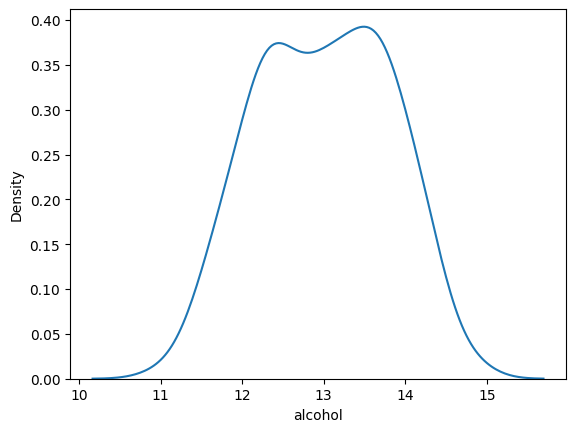

In [8]:
sns.kdeplot(df['alcohol'])

<Axes: xlabel='alcohol', ylabel='malic acid'>

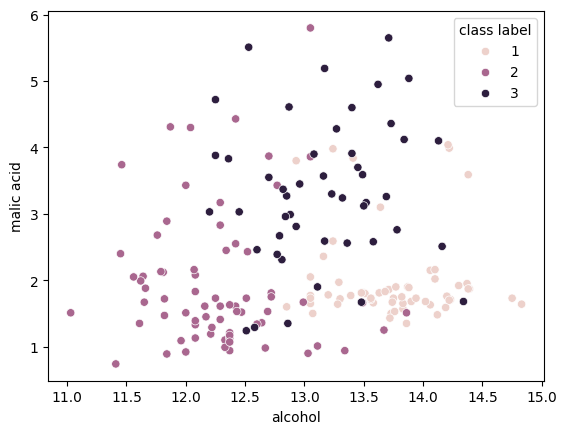

In [10]:
sns.scatterplot(x=df['alcohol'],y=df['malic acid'],hue=df['class label'])

In [17]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(df.drop('class label',axis=1),df['class label'],test_size=0.3,random_state=42)
x_train.shape,x_test.shape

((124, 2), (54, 2))

In [20]:
from sklearn.preprocessing import MinMaxScaler
scaler=MinMaxScaler()
scaler.fit(x_train)
x_train_scaled=scaler.transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [26]:
x_train_scaled=pd.DataFrame(x_train_scaled,columns=x_train.columns)
x_test_scaled=pd.DataFrame(x_test_scaled,columns=x_test.columns)
np.round(x_train_scaled.describe(),1)

,alcohol,malic acid
count,124.0,124.0
mean,0.5,0.3
std,0.2,0.2
min,0.0,0.0
25%,0.3,0.2
50%,0.5,0.2
75%,0.7,0.5
max,1.0,1.0


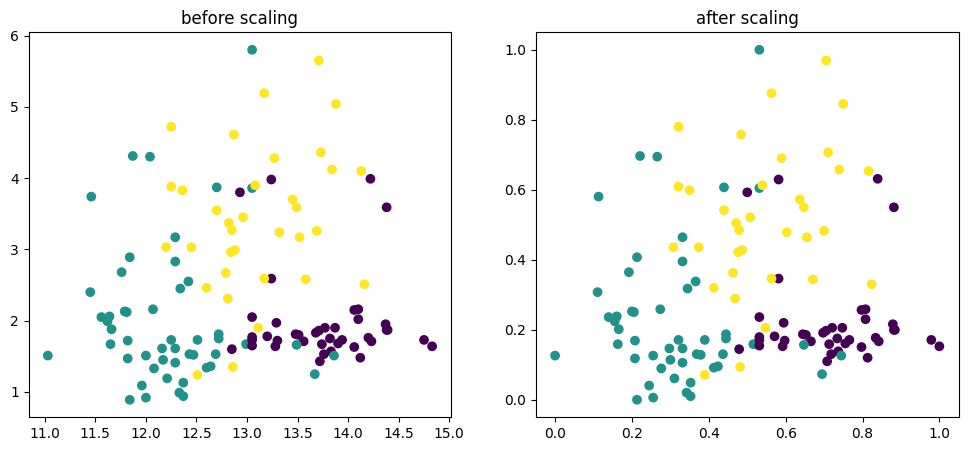

In [29]:
fig,(ax1,ax2)=plt.subplots(ncols=2,figsize=(12,5))
ax1.scatter(x_train['alcohol'],x_train['malic acid'],c=y_train)
ax1.set_title("before scaling")
ax2.scatter(x_train_scaled['alcohol'],x_train_scaled['malic acid'],c=y_train)
ax2.set_title("after scaling")
plt.show()

<Axes: title={'center': 'after scaling'}, xlabel='alcohol', ylabel='Density'>

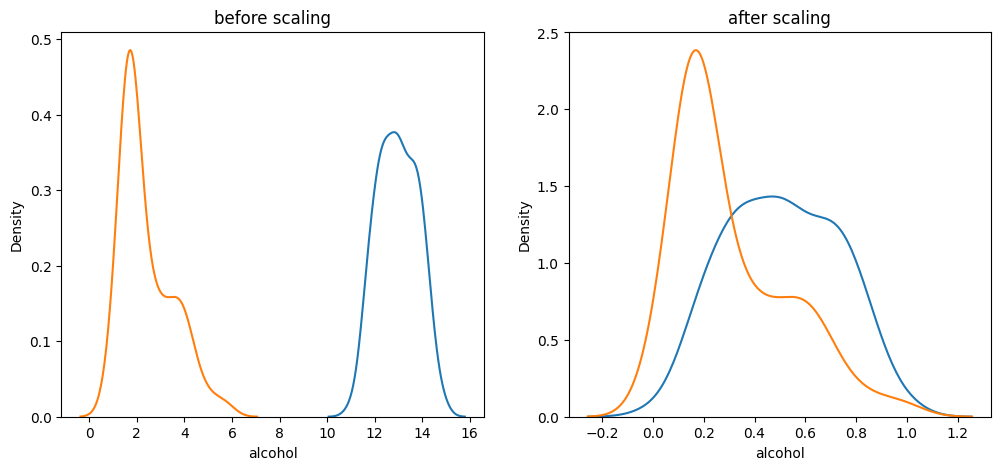

In [30]:
fig,(ax1,ax2)=plt.subplots(ncols=2,figsize=(12,5))
ax1.set_title('before scaling')
sns.kdeplot(x_train['alcohol'],ax=ax1)
sns.kdeplot(x_train['malic acid'],ax=ax1)
ax2.set_title('after scaling')
sns.kdeplot(x_train_scaled['alcohol'],ax=ax2)
sns.kdeplot(x_train_scaled['malic acid'],ax=ax2)

<Axes: title={'center': 'alcohol after scaling'}, xlabel='alcohol', ylabel='Density'>

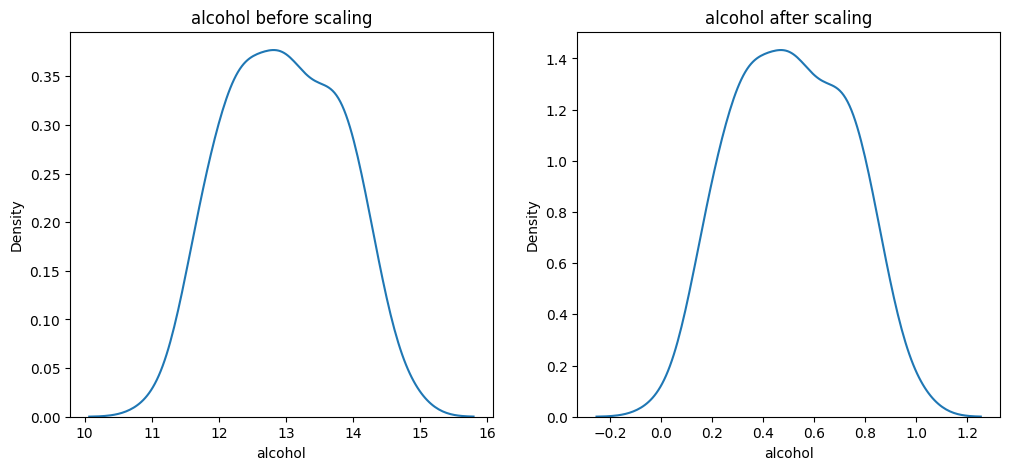

In [31]:
fig,(ax1,ax2)=plt.subplots(ncols=2,figsize=(12,5))
ax1.set_title('alcohol before scaling')
sns.kdeplot(x_train['alcohol'],ax=ax1)
ax2.set_title('alcohol after scaling')
sns.kdeplot(x_train_scaled['alcohol'],ax=ax2)

<Axes: title={'center': 'malic acid after scaling'}, xlabel='malic acid', ylabel='Density'>

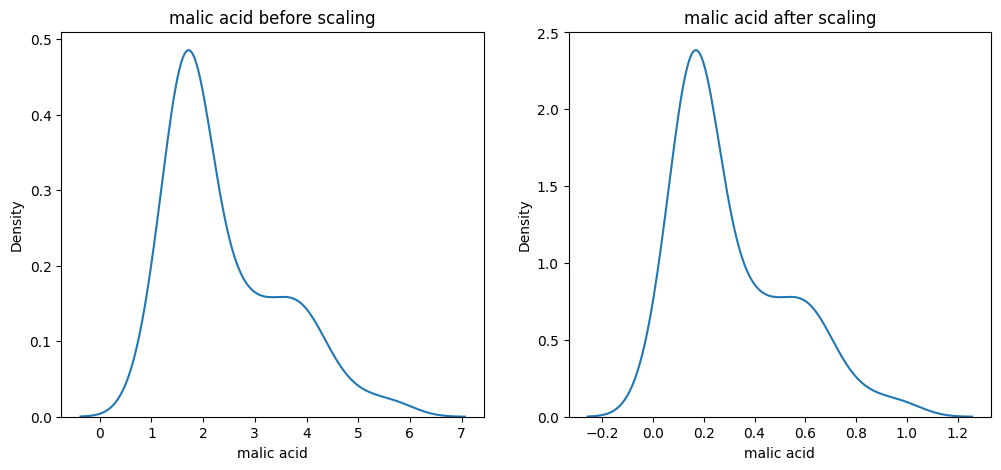

In [32]:
fig,(ax1,ax2)=plt.subplots(ncols=2,figsize=(12,5))
ax1.set_title('malic acid before scaling')
sns.kdeplot(x_train['malic acid'],ax=ax1)
ax2.set_title('malic acid after scaling')
sns.kdeplot(x_train_scaled['malic acid'],ax=ax2)